# 07 · Comparison Plots

Comparison plots generated from the result files written by scripts 03-05.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent          # run this notebook from the notebooks/ folder
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

from pathsnap import config as C

In [2]:
R, F = C.RESULTS, C.FIGURES
BLUE, ORANGE, GREY, RED = "#1565c0", "#ef6c00", "#9e9e9e", "#c62828"
comp = pd.read_csv(R / "model_comparison.csv")
order = ["GaussianNB", "LogisticRegression", "KNN", "DecisionTree", "RandomForest", "MLP", "LightGBM", "XGBoost"]
comp = comp.set_index("model").loc[[m for m in order if m in set(comp.model)]].reset_index()
cv = pd.read_csv(R / "cv_folds.csv")

### 1. CV macro F1 (mean +- std, with fold points)

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(comp))
ax.bar(x, comp.cv_f1_macro_mean, yerr=comp.cv_f1_macro_std, color=BLUE, alpha=.8, capsize=4)
for i, m in enumerate(comp.model):
    v = cv[cv.model == m].f1_macro; ax.scatter(np.full(len(v), i) + np.linspace(-.15, .15, len(v)), v, s=10, c="k", zorder=3)
ax.set_xticks(x, comp.model, rotation=20); ax.set_ylim(0.8, 0.97); ax.set_ylabel("macro F1 (5-fold GroupKFold)")
ax.set_title("Cross-validation macro F1 on the 80 train trips (bars = mean ± std, dots = folds)")
fig.tight_layout(); fig.savefig(F / "cmp_cv_f1.png", dpi=130); plt.close(fig)

### 2. student-test Top-1 and macro F1

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5)); w = .38
ax.bar(x - w / 2, comp.test_top1, w, color=BLUE, label="Top-1 accuracy (observation level)")
ax.bar(x + w / 2, comp.test_f1_macro, w, color=ORANGE, label="macro F1 (candidate level)")
for i in range(len(comp)):
    ax.text(i - w / 2, comp.test_top1[i] + .003, f"{comp.test_top1[i]:.3f}", ha="center", fontsize=7)
    ax.text(i + w / 2, comp.test_f1_macro[i] + .003, f"{comp.test_f1_macro[i]:.3f}", ha="center", fontsize=7)
ax.set_xticks(x, comp.model, rotation=20); ax.set_ylim(0.8, 0.97); ax.legend(loc="lower right")
ax.set_title("Student-test (10 trips) classifier-only performance")
fig.tight_layout(); fig.savefig(F / "cmp_test_top1_f1.png", dpi=130); plt.close(fig)

### 3. log loss

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - w / 2, comp.cv_log_loss, w, color=BLUE, label="CV (train)")
ax.bar(x + w / 2, comp.test_log_loss, w, color=ORANGE, label="student test")
ax.set_yscale("log"); ax.set_xticks(x, comp.model, rotation=20); ax.set_ylabel("log loss (log scale, lower is better)")
ax.legend(); ax.set_title("Probability quality: log loss"); fig.tight_layout(); fig.savefig(F / "cmp_log_loss.png", dpi=130); plt.close(fig)

### 4. accuracy vs inference cost

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(comp.inference_ms_per_1k_rows, comp.test_top1, s=60, c=BLUE)
for _, r in comp.iterrows():
    ax.annotate(r.model, (r.inference_ms_per_1k_rows, r.test_top1), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("inference time (ms per 1,000 candidate rows, log)"); ax.set_ylabel("student-test Top-1")
ax.set_title("Accuracy vs inference cost"); fig.tight_layout(); fig.savefig(F / "cmp_speed_accuracy.png", dpi=130); plt.close(fig)

### 5. train vs CV vs test Top-1 (over/under-fitting evidence)

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5)); w = .27
ax.bar(x - w, comp.train_top1, w, color=GREY, label="train (fit data)")
ax.bar(x, comp.cv_top1_mean, w, color=BLUE, label="CV held-out trips")
ax.bar(x + w, comp.test_top1, w, color=ORANGE, label="student test")
ax.set_xticks(x, comp.model, rotation=20); ax.set_ylim(0.8, 1.0); ax.set_ylabel("Top-1 accuracy"); ax.legend(ncol=3)
ax.set_title("Train vs held-out Top-1: gap indicates overfitting"); fig.tight_layout(); fig.savefig(F / "cmp_fit_gap.png", dpi=130); plt.close(fig)

### 6. confusion matrices (candidate level, threshold 0.5, student test)

In [8]:
n = len(comp); cols = 4; rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3 * rows))
for ax, m in zip(axes.ravel(), comp.model):
    s = pd.read_pickle(R / "preds" / f"test_scores_{m}.pkl")
    cm = confusion_matrix(s.label, (s.p >= .5).astype(int), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > .5 else "black")
    ax.set_xticks([0, 1], ["pred 0", "pred 1"]); ax.set_yticks([0, 1], ["true 0", "true 1"]); ax.set_title(m, fontsize=10)
for ax in axes.ravel()[n:]:
    ax.axis("off")
fig.suptitle("Row-normalised confusion matrices, candidate level, student test (threshold 0.5)")
fig.tight_layout(); fig.savefig(F / "cmp_confusion_matrices.png", dpi=130); plt.close(fig)

### 7. training histories (only models that really have them)

In [9]:
hs = [(m, R / f"history_{m}.csv") for m in ("MLP", "LightGBM", "XGBoost") if (R / f"history_{m}.csv").exists()]
fig, axes = plt.subplots(1, len(hs), figsize=(5 * len(hs), 3.8))
for ax, (m, f) in zip(np.atleast_1d(axes), hs):
    h = pd.read_csv(f)
    if m == "MLP":
        ax.plot(h.epoch, h.train_loss, color=BLUE, label="train loss (log loss)")
        ax2 = ax.twinx(); ax2.plot(h.epoch, h.val_accuracy, color=ORANGE, label="val accuracy"); ax2.set_ylabel("val accuracy")
        ax.set_xlabel("epoch"); ax.legend(loc="upper center"); ax2.legend(loc="center right")
    else:
        ax.plot(h.iteration, h.train_logloss, color=BLUE, label="train"); ax.plot(h.iteration, h.val_logloss, color=ORANGE, label="validation (fold 0 trips)")
        ax.set_xlabel("boosting iteration"); ax.legend()
    ax.set_ylabel("log loss"); ax.set_title(m)
fig.suptitle("Training / validation loss histories"); fig.tight_layout(); fig.savefig(F / "cmp_training_curves.png", dpi=130); plt.close(fig)

### 8. HMM: classifier-only vs HMM per trip

In [10]:
if (R / "hmm_comparison_per_trip.csv").exists():
    per = pd.read_csv(R / "hmm_comparison_per_trip.csv", dtype={"trip": str})
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5)); xx = np.arange(len(per)); w = .4
    ax[0].bar(xx - w / 2, per.cls_top1, w, color=GREY, label="classifier only"); ax[0].bar(xx + w / 2, per.hmm_top1, w, color=RED, label="classifier + HMM")
    ax[0].set_xticks(xx, per.trip, rotation=45); ax[0].set_ylim(.5, 1); ax[0].set_ylabel("Top-1 accuracy"); ax[0].legend(loc="lower left")
    ax[0].set_title("Observation-level Top-1 per student-test trip")
    ax[1].bar(xx - w / 2, per.cls_continuity, w, color=GREY, label="classifier only"); ax[1].bar(xx + w / 2, per.hmm_continuity, w, color=RED, label="classifier + HMM")
    ax[1].set_xticks(xx, per.trip, rotation=45); ax[1].set_ylim(.5, 1.01); ax[1].set_ylabel("route continuity"); ax[1].legend(loc="lower left")
    ax[1].set_title("Route continuity per student-test trip")
    fig.tight_layout(); fig.savefig(F / "hmm_per_trip.png", dpi=130); plt.close(fig)
if (R / "hmm_all_models.csv").exists():
    h = pd.read_csv(R / "hmm_all_models.csv").set_index("model")
    h = h.loc[[m for m in order if m in h.index]].reset_index()
    fig, ax = plt.subplots(figsize=(10, 4.5)); xx = np.arange(len(h)); w = .4
    ax.bar(xx - w / 2, h.cls_top1, w, color=GREY, label="classifier only"); ax.bar(xx + w / 2, h.hmm_top1, w, color=RED, label="classifier + HMM")
    for i in range(len(h)):
        ax.text(i + w / 2, h.hmm_top1[i] + .003, f"{h.hmm_top1[i]:.3f}", ha="center", fontsize=7)
    ax.set_xticks(xx, h.model, rotation=20); ax.set_ylim(.8, 1); ax.set_ylabel("student-test Top-1"); ax.legend(loc="lower right")
    ax.set_title("Effect of HMM/Viterbi decoding on every model's emissions")
    fig.tight_layout(); fig.savefig(F / "hmm_all_models.png", dpi=130); plt.close(fig)
if (R / "hmm_decoder_grid.csv").exists():
    g = pd.read_csv(R / "hmm_decoder_grid.csv")
    fig, ax = plt.subplots(figsize=(7, 4))
    for (we, nop), s in g.groupby(["w_e", "no_path_logp"]):
        s = s.sort_values("beta"); ax.plot(s.beta, s.train_oof_top1, marker="o", label=f"w_e={we}, no-path={nop}")
    ax.set_xscale("log"); ax.set_xlabel("beta (m)"); ax.set_ylabel("Top-1 (train OOF, 30 trips)"); ax.legend(fontsize=7)
    ax.set_title("HMM decoder parameter search"); fig.tight_layout(); fig.savefig(F / "hmm_decoder_grid.png", dpi=130); plt.close(fig)
print("plots written")

plots written


### Saved figures

cmp_confusion_matrices.png


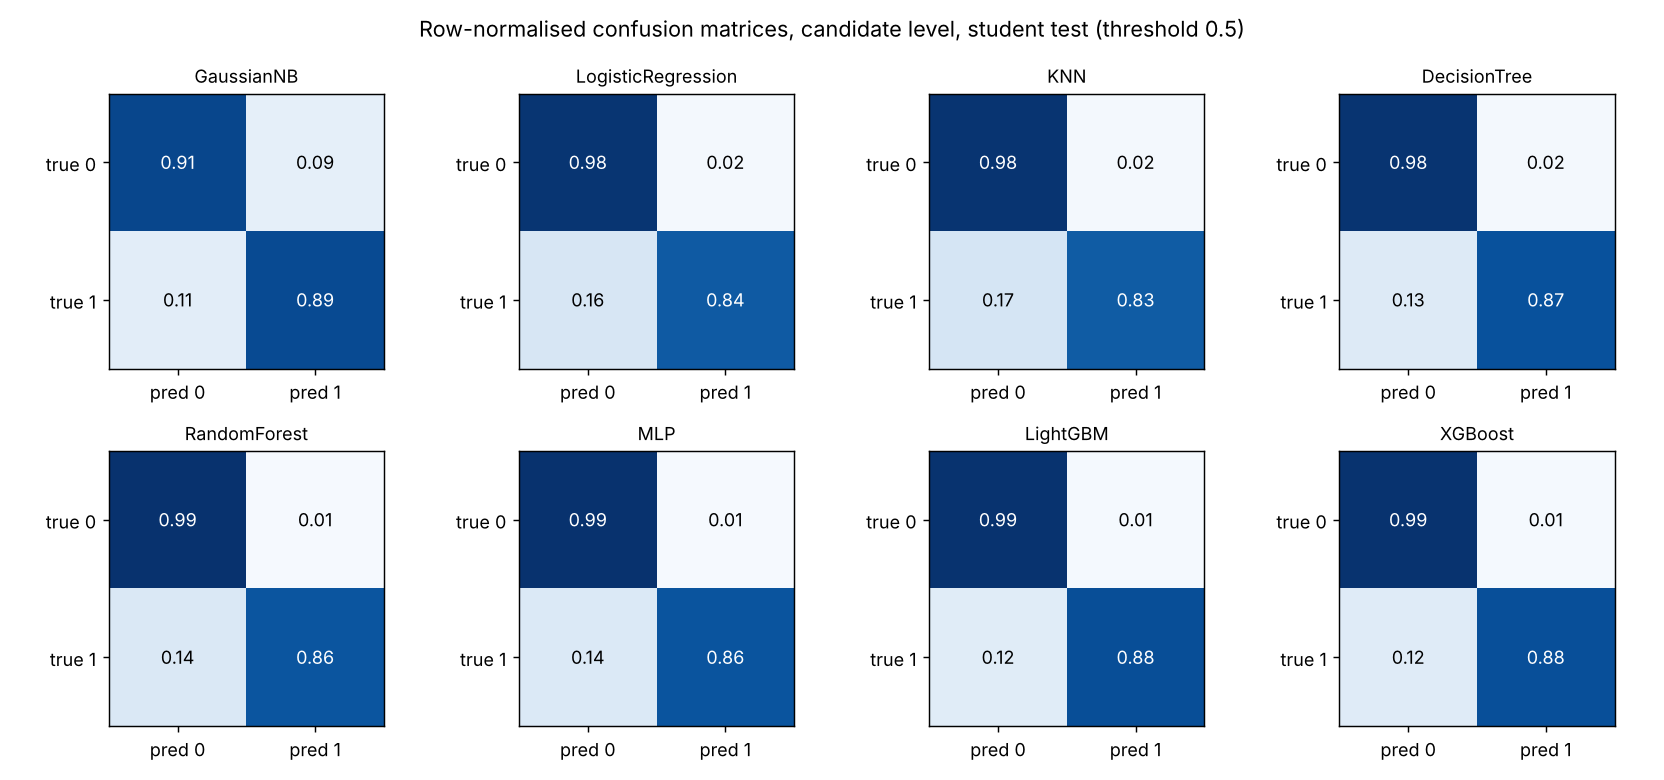

cmp_cv_f1.png


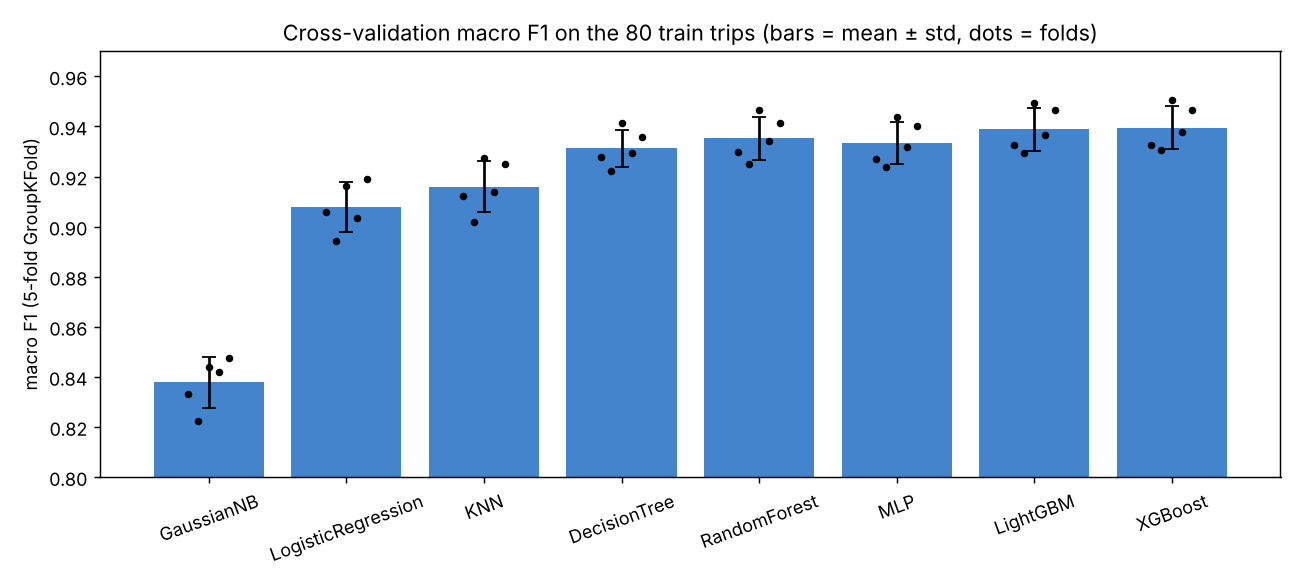

cmp_fit_gap.png


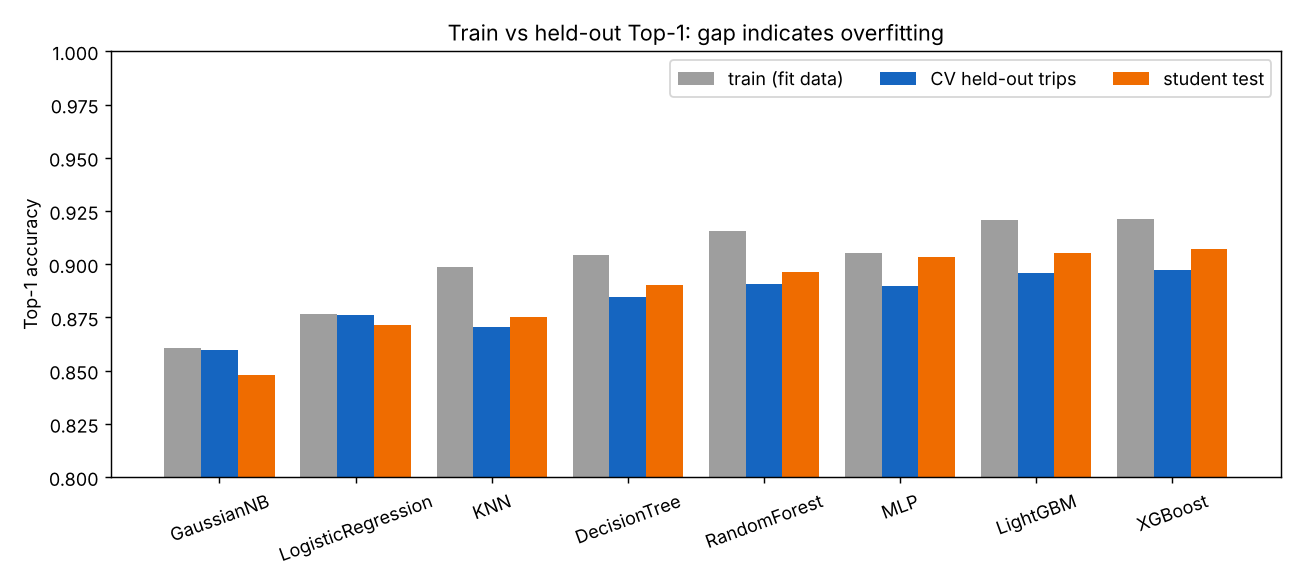

cmp_log_loss.png


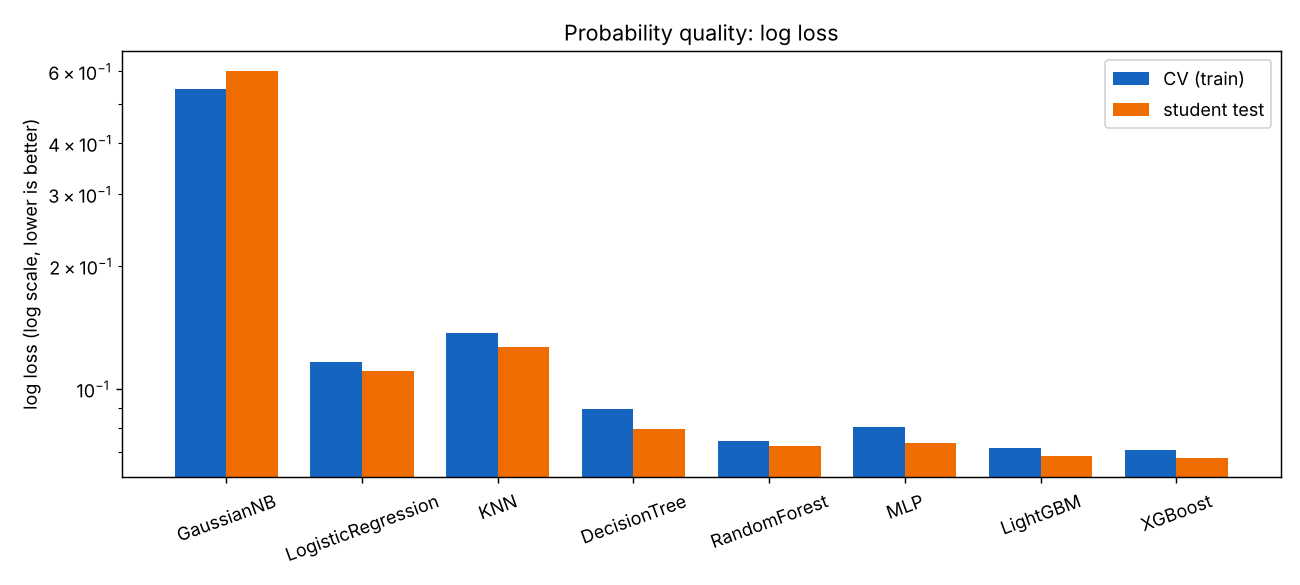

cmp_speed_accuracy.png


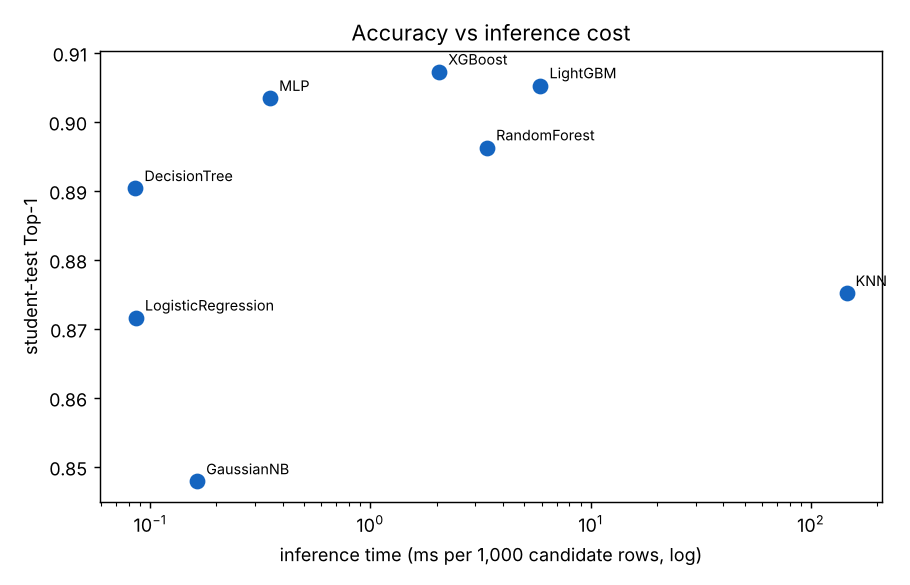

cmp_test_top1_f1.png


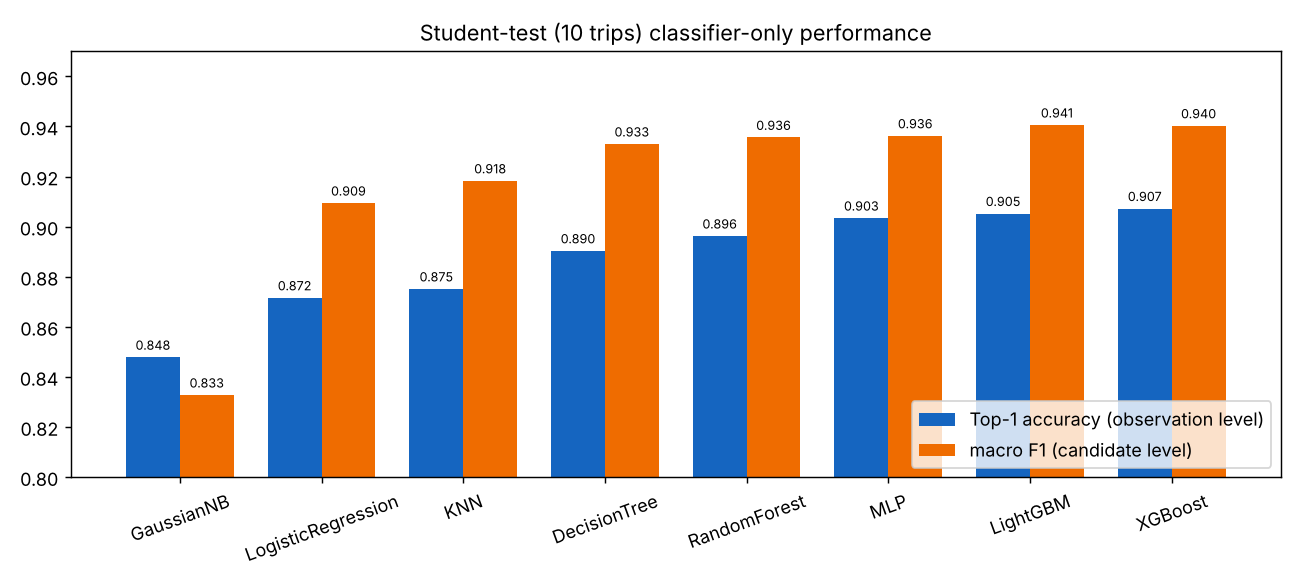

cmp_training_curves.png


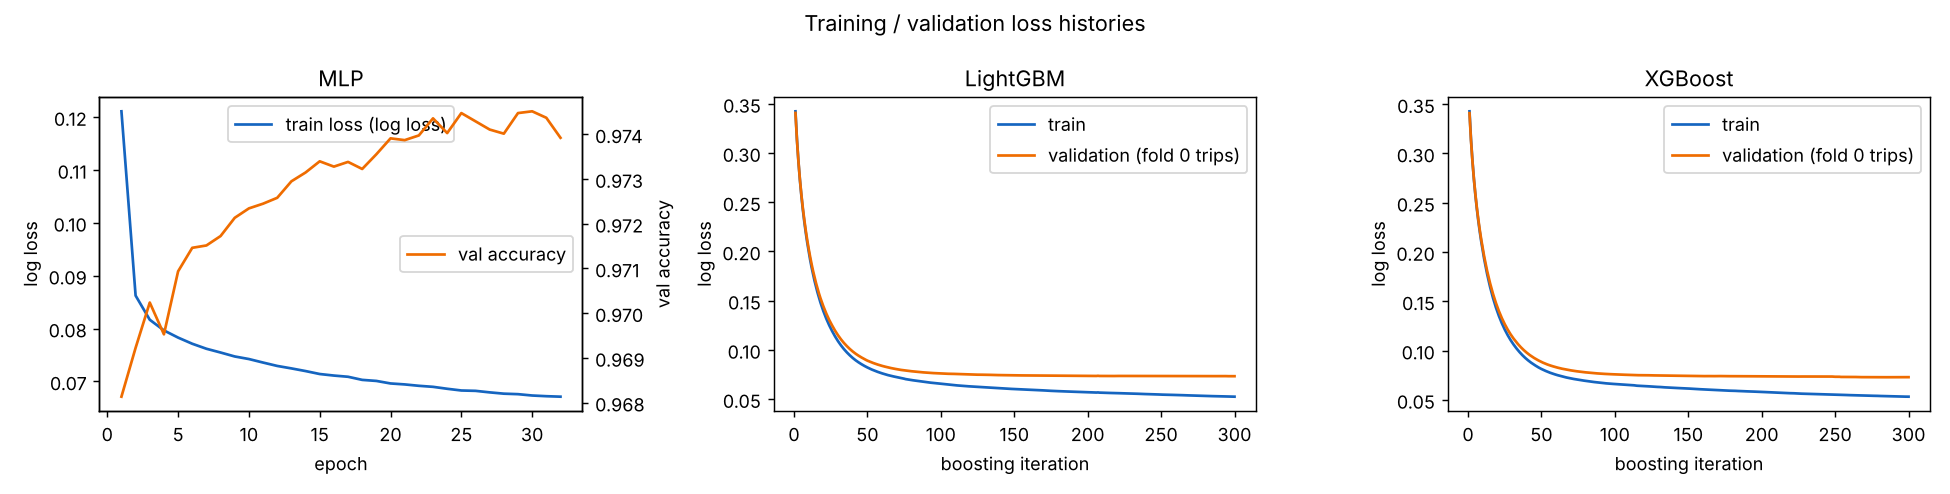

hmm_all_models.png


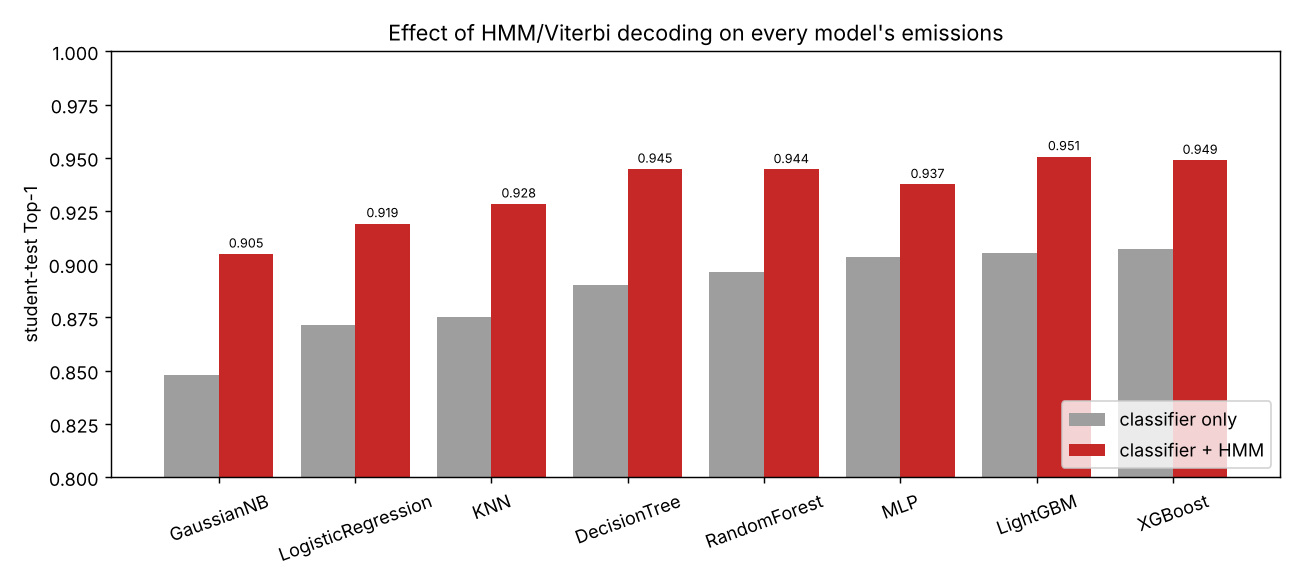

hmm_decoder_grid.png


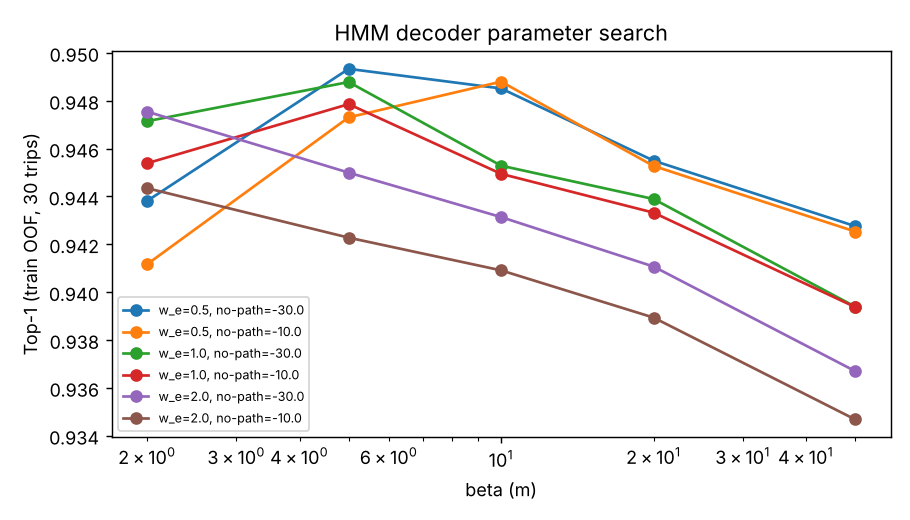

hmm_per_trip.png


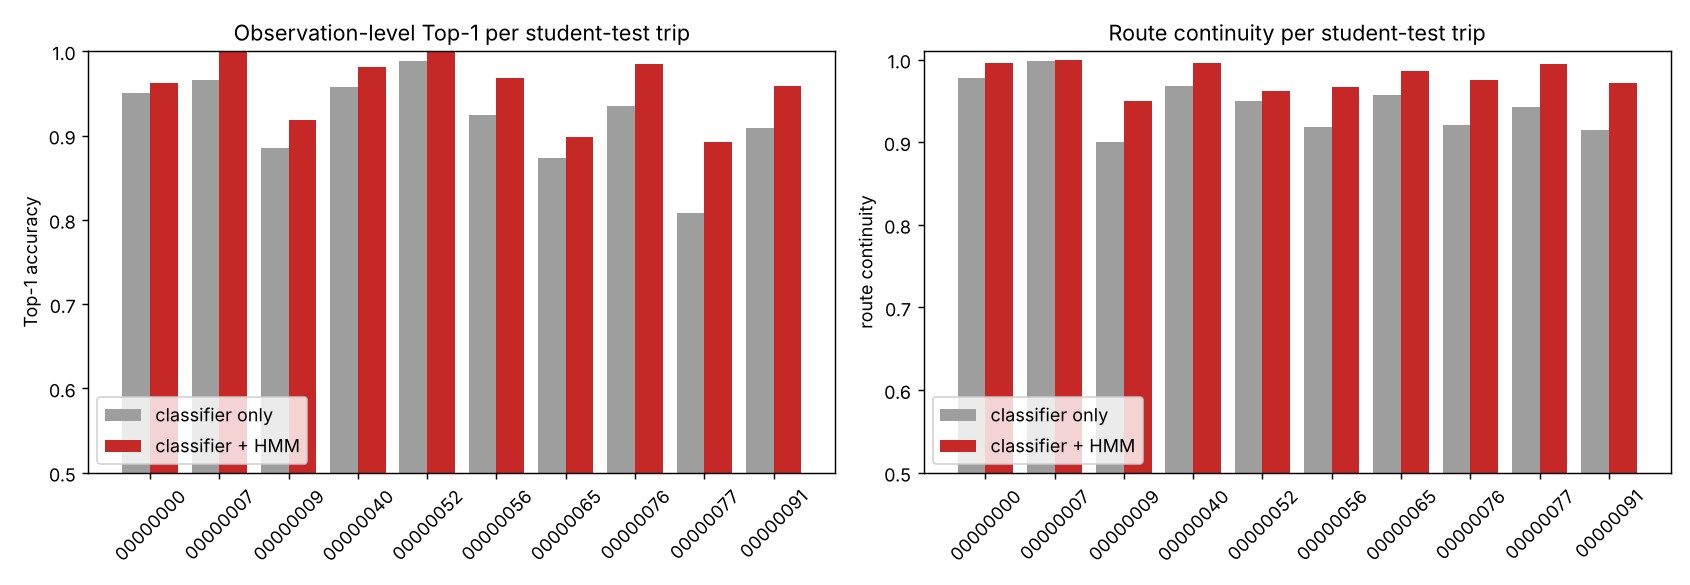

In [11]:
from IPython.display import Image, display
for f in sorted(C.FIGURES.glob("*[cmh][mm][pm]_*.png")):
    print(f.name); display(Image(str(f), width=800))